# Milestone 3 - Complete notebook (Q1 to Q9)
Single compiled notebook for GitHub: `notebooks/milestone-3-questions.ipynb` (branch `milestone-3`). It merges the four part-notebooks into one, in this order:

| Part | Questions | What it does | Needs |
|---|---|---|---|
| A | Q1, Q3, Q4 | Feature-map geometry, grayscale adaptation of a pretrained first layer, dilated convolutions | CPU is enough |
| B | Q5, Q6, Q7 | Soft Dice loss, sigmoid vs softmax heads, compound loss gradients | CPU is enough |
| C | Q2, Q9 (parameters) | Parameter audit of ResNet-34 and EfficientNet-B0 U-Nets | internet for `pip install segmentation-models-pytorch` |
| D | Q8, Q9 (training) | 5-epoch runs: scratch vs pretrained, ResNet-34 vs EfficientNet-B0, logged to W&B | **Kaggle**, GPU on, internet on, `milestone-1` output attached, secret `WANDB_API_KEY` |

Parts A to C run anywhere. Part D runs only when `RUN_TRAINING` is `True` (it is switched on automatically on Kaggle). Every answer line printed in the form's format is also stored in the dictionary `ANSWERS`, printed in the last cell.

The cells titled *(my answer)* are for **your own words**; they are left empty on purpose because the viva tests whether you understand them.

## 0. Setup (shared by all parts)

In [1]:
import os, glob, random, time, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
try:
    import cv2                                                   # only needed by Part D (reading images)
except ImportError:
    cv2 = None

try:
    import segmentation_models_pytorch as smp
except ImportError:                                              # needs internet ON in the notebook settings
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch"], check=True)
    import segmentation_models_pytorch as smp
print("segmentation_models_pytorch", smp.__version__)

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
print("PyTorch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if USE_AMP else "(no GPU)")

IMG_H, IMG_W = 128, 800
CANVAS_PIXELS = IMG_H * IMG_W
DEFECTS = ["defect_a", "defect_b", "defect_c", "defect_d"]
IMG_MEAN, IMG_STD = 0.3314, 0.1892
CFG = dict(epochs=5, batch_size=16, lr=3e-4, weight_decay=1e-2, alpha=0.5, beta=0.5, smooth=1.0, num_workers=4, seed=42)

RUN_TRAINING = os.path.exists("/kaggle/input")   # Part D needs the Kaggle data; set False to skip it, True to force it
DEBUG = False                                    # True: tiny subset, 1 epoch, to test Part D quickly
RUN_CONTROL = True                               # Part D: also train the random-initialised ResNet-34 U-Net
if DEBUG:
    CFG["epochs"] = 1
if RUN_TRAINING and not USE_AMP:
    print("WARNING: Part D will be very slow without a GPU - turn the GPU on.")
print("RUN_TRAINING =", RUN_TRAINING, "|", CFG)

ANSWERS = {}                                     # every answer line is collected here and printed at the end

segmentation_models_pytorch 0.6.0
PyTorch 2.11.0+cu130 | device: cuda Tesla T4
RUN_TRAINING = True | {'epochs': 5, 'batch_size': 16, 'lr': 0.0003, 'weight_decay': 0.01, 'alpha': 0.5, 'beta': 0.5, 'smooth': 1.0, 'num_workers': 4, 'seed': 42}


# PART A - Q1, Q3, Q4: feature-map geometry, grayscale adaptation, dilated convolutions
Each section derives the quantity from first principles, verifies it with PyTorch layers, and prints one line in the answer format of the form.

## Q1 - Feature-map geometry and downsampling
Max-pooling with kernel 2 and stride 2 maps a size `n` to `floor(n / 2)`; the decoder doubles sizes with a stride-2 transposed convolution. A skip connection needs equal height and width, so an odd size at any stage produces a mismatch of one pixel.

In [2]:
def encoder_sizes(h, w, stages=4):
    sizes = [(h, w)]
    for _ in range(stages):
        sizes.append((sizes[-1][0] // 2, sizes[-1][1] // 2))
    return sizes

def skip_check(h, w, stages=4):
    """Per decoder level: doubled size of the previous map vs the encoder map it is concatenated with."""
    enc = encoder_sizes(h, w, stages)
    cur, rows = enc[-1], []
    for level in range(stages, 0, -1):
        up, skip = (cur[0] * 2, cur[1] * 2), enc[level - 1]
        rows.append(dict(joins_with_stage=level - 1, upsampled=up, skip=skip, height_gap=skip[0] - up[0], width_gap=skip[1] - up[1]))
        cur = skip
    return pd.DataFrame(rows)

enc = encoder_sizes(128, 800)
print("128 x 800 encoder sizes:", enc)
print(skip_check(128, 800).to_string(index=False))
print("\n128 x 799 encoder sizes:", encoder_sizes(128, 799))
gaps = skip_check(128, 799)
print(gaps.to_string(index=False))

# the same with real layers: the first concatenation already fails for an odd width
pool, up = nn.MaxPool2d(2, 2), nn.ConvTranspose2d(1, 1, 2, stride=2)
x = torch.zeros(1, 1, 128, 799)
for _ in range(3):
    x = pool(x)                                  # stages 1, 2, 3
stage3 = x
dec = up(pool(stage3))                           # bottleneck, then doubled again
real_gap = stage3.shape[-1] - dec.shape[-1]
try:
    torch.cat([dec, stage3], dim=1)
except RuntimeError as e:
    print("torch.cat error:", str(e)[:110])

128 x 800 encoder sizes: [(128, 800), (64, 400), (32, 200), (16, 100), (8, 50)]
 joins_with_stage  upsampled       skip  height_gap  width_gap
                3  (16, 100)  (16, 100)           0          0
                2  (32, 200)  (32, 200)           0          0
                1  (64, 400)  (64, 400)           0          0
                0 (128, 800) (128, 800)           0          0

128 x 799 encoder sizes: [(128, 799), (64, 399), (32, 199), (16, 99), (8, 49)]
 joins_with_stage  upsampled       skip  height_gap  width_gap
                3   (16, 98)   (16, 99)           0          1
                2  (32, 198)  (32, 199)           0          1
                1  (64, 398)  (64, 399)           0          1
                0 (128, 798) (128, 799)           0          1
torch.cat error: Sizes of tensors must match except in dimension 1. Expected size 98 but got size 99 for tensor number 1 in the


In [3]:
Hb, Wb = enc[-1]
factor = (128 * 800) / (Hb * Wb)
width_gaps = set(gaps["width_gap"].abs())
assert width_gaps == {real_gap}, width_gaps          # every level, and the real layers, give the same gap
print(f"Q1 H_bottle, W_bottle; mismatch_px; downsample_factor: {Hb}, {Wb}; {real_gap}; {factor:g}")
ANSWERS["Q1"] = dict(H_bottle=Hb, W_bottle=Wb, mismatch_px=real_gap, downsample_factor=factor)

Q1 H_bottle, W_bottle; mismatch_px; downsample_factor: 8, 50; 1; 256


## Q3 - Grayscale adaptation of a pretrained first layer
With the gray image duplicated over three channels, `conv1` computes `sum_c sum_ij W[c,i,j] * I[i,j] = sum_ij (sum_c W[c,i,j]) * I[i,j]`. A one-channel layer reproduces this exactly when its weights are the channel-wise combination that appears in this expression. The check below tests both candidates on random weights and a random batch.

In [4]:
torch.manual_seed(0)
conv3 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
I = torch.rand(2, 1, 128, 800)
out_A = conv3(I.repeat(1, 3, 1, 1))                                   # Strategy A: channel duplication

def one_channel_layer(weight):
    c = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    c.weight.data.copy_(weight)
    return c

W = conv3.weight.data
results = {}
for name, w_gray in {"sum": W.sum(dim=1, keepdim=True), "mean": W.mean(dim=1, keepdim=True)}.items():
    err = (out_A - one_channel_layer(w_gray)(I)).abs().max().item()
    results[name] = err
    print(f"{name:5s}: max |A - B| = {err:.2e}")
matching = min(results, key=results.get)
assert results[matching] < 1e-4 and results[({"sum", "mean"} - {matching}).pop()] > 1e-2

batch_A, batch_B = torch.zeros(16, 3, 128, 800), torch.zeros(16, 1, 128, 800)
mem_factor = (batch_A.numel() * batch_A.element_size()) / (batch_B.numel() * batch_B.element_size())
print(f"Q3 sum_or_mean, memory_factor: {matching}, {mem_factor:g}")
ANSWERS["Q3"] = dict(sum_or_mean=matching, memory_factor=mem_factor)

sum  : max |A - B| = 8.94e-07
mean : max |A - B| = 9.95e-01
Q3 sum_or_mean, memory_factor: sum, 3


## Q4 - Atrous (dilated) convolutions
Effective footprint of a `k x k` kernel with dilation `r`: `k' = k + (k - 1)(r - 1)`. The number of weights does not depend on `r`. The footprint is verified by convolving a single bright pixel with an all-ones kernel and measuring the extent of the non-zero response.

In [5]:
def footprint_formula(k, r):
    return k + (k - 1) * (r - 1)

def footprint_measured(k, r, size=81):
    conv = nn.Conv2d(1, 1, kernel_size=k, dilation=r, padding=footprint_formula(k, r) // 2, bias=False)
    conv.weight.data.fill_(1.0)
    x = torch.zeros(1, 1, size, size); x[0, 0, size // 2, size // 2] = 1.0
    rows = torch.nonzero(conv(x)[0, 0].abs().sum(dim=1))
    return int(rows.max() - rows.min() + 1)

table = pd.DataFrame([dict(r=r, formula=footprint_formula(3, r), measured=footprint_measured(3, r),
                           weights=nn.Conv2d(1, 1, 3, dilation=r, bias=False).weight.numel()) for r in [1, 2, 6, 12]])
print(table.to_string(index=False))
assert (table["formula"] == table["measured"]).all()
k6, k12 = footprint_formula(3, 6), footprint_formula(3, 12)
print(f"Q4 k_eff_r6, k_eff_r12: {k6}, {k12}")
ANSWERS["Q4"] = dict(k_eff_r6=k6, k_eff_r12=k12)

 r  formula  measured  weights
 1        3         3        9
 2        5         5        9
 6       13        13        9
12       25        25        9
Q4 k_eff_r6, k_eff_r12: 13, 25


### Q4, part 2: advantage of ASPP over a pooling bottleneck (my answer)
*(Write 1 to 2 sentences in your own words here, covering: what each dilation rate sees, what happens to the resolution, and what a pooling bottleneck discards. The toy ASPP in the learning notebook shows the output keeps the height and width of its input.)*

# PART B - Q5, Q6, Q7: Dice loss, output heads, compound loss
Q5 is computed from the formula; Q6 is tested on toy masks; Q7 is measured with autograd.

## Q5 - Soft Dice loss with additive smoothing (epsilon = 1)
`Loss = 1 - (2 * sum(p*y) + eps) / (sum(p) + sum(y) + eps)` on a patch of 10,000 pixels with 100 defect pixels.

In [6]:
def soft_dice_loss(p, y, eps=1.0):
    return 1 - (2 * (p * y).sum() + eps) / (p.sum() + y.sum() + eps)

n, n_def = 10_000, 100
y = torch.zeros(n); y[:n_def] = 1
p_lazy = torch.full((n,), 0.01)                          # Model 1
p_acc = torch.zeros(n); p_acc[:n_def] = 0.90             # Model 2
loss1, loss2 = soft_dice_loss(p_lazy, y).item(), soft_dice_loss(p_acc, y).item()
print(f"Q5 loss_model1, loss_model2: {loss1:.4f}, {loss2:.4f}")
ANSWERS["Q5"] = dict(loss_model1=round(loss1, 4), loss_model2=round(loss2, 4))

Q5 loss_model1, loss_model2: 0.9851, 0.0524


## Q6 - Sigmoid versus softmax output heads
A 5-way softmax needs one class index per pixel. The test converts masks to a label map and back. First without overlap (defect a left, defect c right), then with overlapping defects.

In [7]:
H, W = 8, 20
def blank(): return np.zeros((H, W), dtype=np.uint8)

def to_label_map(masks):
    label = np.zeros((H, W), dtype=np.int64)
    for k in sorted(masks):
        label[masks[k] == 1] = k                          # shared pixels keep only the last class
    return label

def roundtrip(masks):
    label = to_label_map(masks)
    return {k: (label == k).astype(np.uint8) for k in masks}

a, c = blank(), blank(); a[2:6, 1:9] = 1; c[1:7, 12:19] = 1
masks = {1: a, 3: c}
ok = all((roundtrip(masks)[k] == masks[k]).all() for k in masks)
print("non-overlapping strip, both defects recoverable from one label map:", ok)

a2, c2 = blank(), blank(); a2[2:6, 4:12] = 1; c2[3:7, 8:16] = 1
masks2 = {1: a2, 3: c2}
back2 = roundtrip(masks2)
print("overlapping strip: pixels per class (true / after conversion):", {k: (int(masks2[k].sum()), int(back2[k].sum())) for k in masks2},
      "| shared pixels:", int((a2 & c2).sum()))

z = torch.tensor([-4.0, 5.0, -4.0, 5.0, -4.0])
print("softmax on a pixel that is both a and c:", F.softmax(z, 0).numpy().round(3), "| sigmoid:", torch.sigmoid(torch.tensor([5.0, -4.0, 5.0, -4.0])).numpy().round(3))
print(f"Q6 Yes/No (both defects segmentable on one strip without interference): {'Yes' if ok else 'No'}")
ANSWERS["Q6"] = "Yes" if ok else "No"

non-overlapping strip, both defects recoverable from one label map: True
overlapping strip: pixels per class (true / after conversion): {1: (32, 20), 3: (32, 32)} | shared pixels: 12
softmax on a pixel that is both a and c: [0.  0.5 0.  0.5 0. ] | sigmoid: [0.993 0.018 0.993 0.018]
Q6 Yes/No (both defects segmentable on one strip without interference): Yes


### Q6, part 2: disadvantage of the softmax formulation (my answer)
*(One sentence in your own words: what can a pixel's probability vector represent under softmax, what does the overlap experiment show happens to a pixel with two labels, and what does the sigmoid head do instead?)*

## Q7 - Compound loss on clean images
On a clean image `Loss_Dice = 1 - 1/(S+1)` with `S = sum(p)`; its derivative with respect to every probability is `1/(S+1)^2`, and the chain rule through the sigmoid multiplies it by `p(1-p)`. The table measures the actual logit gradients of Dice and BCE in three situations.

In [8]:
N = 10_000
y0 = torch.zeros(N)

def dice_loss_logits(z, y, eps=1.0):
    p = torch.sigmoid(z)
    return 1 - (2 * (p * y).sum() + eps) / (p.sum() + y.sum() + eps)

stray = torch.full((N,), -10.0); stray[:50] = 6.0
diffuse = torch.full((N,), float(np.log(0.005 / 0.995)))
scenarios = {"clean prediction": (torch.full((N,), -10.0), slice(None)),
             "50 stray confident pixels": (stray, slice(0, 50)),
             "diffuse noise (p=0.005 everywhere)": (diffuse, slice(None))}
rows = []
for name, (z0, where) in scenarios.items():
    z = z0.clone().requires_grad_(True)
    ld = dice_loss_logits(z, y0); ld.backward(); gd = z.grad.clone(); z.grad = None
    lb = F.binary_cross_entropy_with_logits(z, y0); lb.backward(); gb = z.grad.clone()
    S_ = torch.sigmoid(z0).sum().item()
    rows.append(dict(scenario=name, S=S_, dice_loss=ld.item(), dice_logit_grad=gd[where].abs().mean().item(),
                     bce_loss=lb.item(), bce_logit_grad=gb[where].abs().mean().item(), dLdp=1 / (S_ + 1) ** 2))
print(pd.DataFrame(rows).set_index("scenario").to_string(float_format=lambda v: f"{v:.3g}"))

                                       S  dice_loss  dice_logit_grad  bce_loss  bce_logit_grad     dLdp
scenario                                                                                               
clean prediction                   0.454      0.312         2.15e-05  4.58e-05        4.54e-09    0.473
50 stray confident pixels           50.3      0.981         9.36e-07    0.0301        9.98e-05  0.00038
diffuse noise (p=0.005 everywhere)    50       0.98         1.91e-06   0.00501           5e-07 0.000384


### Q7 answers (my words)
**1. Gradient behaviour of Dice on a clean image:** *(describe, using the table: size of the gradient with stray noise versus clean predictions, and what the sigmoid factor does)*

**2. Why BCE + Dice beats Dice alone on imbalanced data:** *(1 to 2 sentences: what BCE gives on clean images and background, what Dice adds for rare foreground)*

# PART C - Q2 and Q9 (parameters): pretrained backbone audit
Parameter counts of `smp.Unet(encoder_name=..., in_channels=1, classes=4)` for ResNet-34 and EfficientNet-B0, the trainable share with a frozen ResNet-34 encoder, the parameter ratio asked in Q9, and the evidence for the convolution technique that makes EfficientNet small. Counts depend on the library version, which is printed above.

In [9]:
def count(m):
    return sum(p.numel() for p in m.parameters())

def build_unet(encoder_name):
    return smp.Unet(encoder_name=encoder_name, encoder_weights=None, in_channels=1, classes=4)   # weights do not change the count

def parts(model):
    return dict(total=count(model), encoder=count(model.encoder), decoder=count(model.decoder), seg_head=count(model.segmentation_head))

def build_effb0():
    for name in ["efficientnet-b0", "tu-efficientnet_b0", "timm-efficientnet-b0"]:
        try:
            return name, build_unet(name)
        except Exception as e:
            print(f"encoder name {name!r} not available:", str(e)[:100])
    raise RuntimeError("no EfficientNet-B0 encoder could be built")

r34 = build_unet("resnet34")
eff_name, eff = build_effb0()
table = pd.DataFrame({"resnet34": parts(r34), eff_name: parts(eff)}).T
print(table.to_string())

                    total   encoder  decoder  seg_head
resnet34         24430532  21278400  3151552       580
efficientnet-b0   6251328   4006972  2243776       580


## Q2 - total parameters and the frozen-encoder share

In [10]:
total_r34, total_eff = table.loc["resnet34", "total"], table.loc[eff_name, "total"]
efficient = "resnet34" if total_r34 < total_eff else eff_name
diff = abs(int(total_r34) - int(total_eff))

m = build_unet("resnet34")
for p in m.encoder.parameters():
    p.requires_grad = False
trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
pct = 100 * trainable / count(m)
print(f"Q2 more_efficient_model, param_diff; trainable_pct: {efficient}, {diff}; {pct:.1f}")
ANSWERS["Q2"] = dict(more_efficient_model=efficient, param_diff=diff, trainable_pct=round(pct, 1))

Q2 more_efficient_model, param_diff; trainable_pct: efficientnet-b0, 18179204; 12.9


## Q9 (parameter parts) - ratio and the convolution technique

In [11]:
ratio = total_r34 / total_eff
print(f"parameter ratio ResNet-34 / EfficientNet-B0 = {ratio:.2f} -> rounded {round(ratio)}")

cin = cout = 128
print(f"standard 3x3 conv (128 -> 128): {3 * 3 * cin * cout:,} weights | per-channel 3x3 + 1x1 mixing: {3 * 3 * cin + cin * cout:,} weights")
rows = []
for name, mod in eff.encoder.named_modules():
    if isinstance(mod, nn.Conv2d):
        kind = "per-channel (groups == in_channels)" if mod.groups == mod.in_channels and mod.groups > 1 else ("1x1" if mod.kernel_size == (1, 1) else "standard")
        rows.append(dict(kind=kind, params=count(mod)))
print(pd.DataFrame(rows).groupby("kind")["params"].agg(["count", "sum"]).to_string())
print(f"Q9 (part) param_ratio: {round(ratio)}")
ANSWERS["Q9_param_ratio"] = round(ratio)

parameter ratio ResNet-34 / EfficientNet-B0 = 3.91 -> rounded 4
standard 3x3 conv (128 -> 128): 147,456 weights | per-channel 3x3 + 1x1 mixing: 17,536 weights
                                     count      sum
kind                                               
1x1                                     64  3782652
per-channel (groups == in_channels)     16   182016
standard                                 1      288
Q9 (part) param_ratio: 4


### Q9, part 4: the convolution technique (my answer)
*(Name the technique and describe in one line how it factorises a standard convolution, using the layer table above.)*

Q9 parts 2 and 3 (peak GPU memory and score of the two U-Nets after 5 epochs) are answered by the training notebook of Part 4.

# PART D - Q8 and Q9: scratch vs pretrained, ResNet-34 vs EfficientNet-B0 (5-epoch runs)
Runs on Kaggle (**GPU on, internet ON**). **Inputs:** competition data; output of `milestone-1` (`holdout.csv`). **Secret:** `WANDB_API_KEY`. If `RUN_TRAINING` is `False`, the cells of this part only define functions and skip everything that needs the data.

Identical settings for every model, as the questions prescribe:

| Setting | Value |
|---|---|
| Optimiser | AdamW, learning rate 3e-4, weight decay 1e-2, constant learning rate |
| Batch size / epochs | 16 / 5 |
| Loss | `CompoundLoss(alpha=0.5, beta=0.5, smooth=1.0)` = 0.5 BCE + 0.5 soft Dice (Dice over all image-class pairs, as in Q7) |
| Data | same stratified split (9,114 train / 2,279 validation), flips + brightness/contrast augmentation on training images, 1 gray channel normalised with the training mean/std |
| Precision | mixed precision (float16 forward, float32 loss) for all models |
| Seed | 42 before every run |

Runs (each logged as its own W&B run):
1. `m3q8-scratch-5ep`: the Milestone-2 scratch U-Net (random initialisation).
2. `m3q8-r34-pretrained-5ep`: smp U-Net with ResNet-34 encoder, ImageNet weights.
3. `m3q9-effb0-pretrained-5ep`: smp U-Net with EfficientNet-B0 encoder, ImageNet weights.
4. `m3q8-r34-random-5ep` (control, optional): same architecture as run 2 with **random** weights. It separates the effect of pretraining from the effect of the architecture.

Measured per run: train and validation loss, official-style score (readings A and B), foreground Dice, parameters, peak GPU memory, time per epoch.

## D1. Data: files, split, RLE, metric, Dataset

In [12]:
def find_file(name, known=None):
    if known and os.path.exists(known):
        return known
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found - attach the right input to this notebook")
    return sorted(hits)[0]

def rle_decode(rle, shape=(IMG_H, IMG_W)):
    flat = np.zeros(shape[0] * shape[1], dtype=np.uint8)
    if isinstance(rle, str) and rle.strip():
        tok = [int(t) for t in rle.split()]
        starts = np.array(tok[0::2]) - 1
        ends = starts + np.array(tok[1::2])
        for s, e in zip(starts, ends):
            flat[max(s, 0):min(e, flat.size)] = 1
    return flat.reshape(shape, order="F")

def dice_empty_aware(inter, pred_area, gt_area):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    denom = pred_area + gt_area
    dice = np.where(denom > 0, 2 * inter / np.maximum(denom, 1), 0.0)
    return np.where((pred_area == 0) & (gt_area == 0), 1.0, dice)

def competition_score(inter, pred_area, gt_area, canvas=CANVAS_PIXELS, weights=(0.70, 0.20, 0.10)):
    inter, pred_area, gt_area = (np.asarray(a, dtype=np.float64) for a in (inter, pred_area, gt_area))
    positive = gt_area > 0
    empty = ~positive
    dice = dice_empty_aware(inter, pred_area, gt_area)
    fg, fp, ea = dice[positive].mean(), 1 - (pred_area[empty] / canvas).mean(), (pred_area[empty] == 0).mean()
    return dict(fg=fg, ea=ea, A=weights[0] * fg + weights[1] * fp + weights[2] * ea, B=0.7 * fg + 0.3 * ea)

def augment_pair(img, masks):
    if random.random() < 0.5:
        img, masks = img[:, ::-1], masks[:, :, ::-1]
    if random.random() < 0.5:
        img, masks = img[::-1, :], masks[:, ::-1, :]
    return np.clip(img * random.uniform(0.8, 1.2) + random.uniform(-0.1, 0.1), 0.0, 1.0), masks

class SurfaceDataset(Dataset):
    """Needs the globals rle_table and IMAGE_INDEX, which are created in the next cell."""
    def __init__(self, image_ids, augment=False):
        self.ids, self.augment = list(image_ids), augment
        self.rows = rle_table.loc[self.ids, DEFECTS].values
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = cv2.imread(IMAGE_INDEX[self.ids[i]], cv2.IMREAD_GRAYSCALE)
        assert img is not None and img.shape == (IMG_H, IMG_W)
        img = img.astype(np.float32) / 255.0
        masks = np.stack([rle_decode(r) for r in self.rows[i]]).astype(np.float32)
        if self.augment:
            img, masks = augment_pair(img, masks)
        img = (img - IMG_MEAN) / IMG_STD
        return torch.from_numpy(np.ascontiguousarray(img))[None].float(), torch.from_numpy(np.ascontiguousarray(masks))

In [13]:
if RUN_TRAINING:
    TRAIN_CSV = find_file("train.csv", "/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv")
    long = pd.read_csv(TRAIN_CSV)
    rle_table = long.pivot(index="image_id", columns="defect_type", values="mask_rle")[DEFECTS]

    def make_holdout(rle_table, val_fraction=0.2, seed=42, path="/kaggle/working/holdout.csv"):
        """Stratified 80/20 split. Each image gets a key = which of the 4 defect types it contains (e.g. '0101');
        keys with fewer than 2 images are merged into 'rare' so the stratified split can work."""
        from sklearn.model_selection import train_test_split
        has = rle_table.notna() & (rle_table.astype(str).apply(lambda c: c.str.strip()) != "")
        key = has.astype(int).astype(str).agg("".join, axis=1)
        key = key.where(key.map(key.value_counts()) >= 2, "rare")
        tr, va = train_test_split(rle_table.index, test_size=val_fraction, stratify=key, random_state=seed)
        out = pd.DataFrame({"image_id": list(tr) + list(va), "split": ["train"] * len(tr) + ["val"] * len(va)})
        out.to_csv(path, index=False)
        print("holdout.csv created:", len(tr), "train /", len(va), "val ->", path)
        return out

    try:                                                    # use the Milestone-1 split if it is attached to the notebook
        hold = pd.read_csv(find_file("holdout.csv"))
        print("using existing holdout.csv")
    except FileNotFoundError:                               # otherwise build it here (same 80/20 stratified idea)
        hold = make_holdout(rle_table)
    is_val = hold["split"].astype(str).str.lower().isin({"val", "valid", "validation", "holdout"})
    val_ids = sorted(set(hold.loc[is_val, "image_id"]))
    train_ids = sorted(set(rle_table.index) - set(val_ids))
    assert len(val_ids) == 2279 and len(train_ids) == 9114, (len(train_ids), len(val_ids))
    IMG_DIR = os.path.dirname(glob.glob(f"/kaggle/input/**/{train_ids[0]}.*", recursive=True)[0])
    IMAGE_INDEX = {os.path.splitext(f)[0]: os.path.join(IMG_DIR, f) for f in os.listdir(IMG_DIR)}
    if DEBUG:
        train_ids, val_ids = train_ids[:64], val_ids[:32]
    print("train images:", len(train_ids), "| validation images:", len(val_ids))

    kw = dict(num_workers=CFG["num_workers"], pin_memory=True, persistent_workers=CFG["num_workers"] > 0)
    train_loader = DataLoader(SurfaceDataset(train_ids, True), batch_size=CFG["batch_size"], shuffle=True, drop_last=True, **kw)
    val_loader = DataLoader(SurfaceDataset(val_ids, False), batch_size=CFG["batch_size"], shuffle=False, **kw)
    print("batches per epoch:", len(train_loader))
else:
    print("RUN_TRAINING is False: data loading skipped (Part D needs the Kaggle input).")

holdout.csv created: 9114 train / 2279 val -> /kaggle/working/holdout.csv
train images: 9114 | validation images: 2279
batches per epoch: 569


## D2. Models

In [14]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x):
        return self.block(x)

class UNetScratch(nn.Module):
    """The Milestone-2 from-scratch U-Net: 4 encoder levels, 1 input channel, 4 logits, 7,762,564 parameters."""
    def __init__(self, in_ch=1, n_classes=4, base=32):
        super().__init__()
        c = [base, base * 2, base * 4, base * 8, base * 16]
        self.enc1, self.enc2 = DoubleConv(in_ch, c[0]), DoubleConv(c[0], c[1])
        self.enc3, self.enc4 = DoubleConv(c[1], c[2]), DoubleConv(c[2], c[3])
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(c[3], c[4])
        self.up4, self.dec4 = nn.ConvTranspose2d(c[4], c[3], 2, stride=2), DoubleConv(c[3] * 2, c[3])
        self.up3, self.dec3 = nn.ConvTranspose2d(c[3], c[2], 2, stride=2), DoubleConv(c[2] * 2, c[2])
        self.up2, self.dec2 = nn.ConvTranspose2d(c[2], c[1], 2, stride=2), DoubleConv(c[1] * 2, c[1])
        self.up1, self.dec1 = nn.ConvTranspose2d(c[1], c[0], 2, stride=2), DoubleConv(c[0] * 2, c[0])
        self.head = nn.Conv2d(c[0], n_classes, kernel_size=1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

def smp_unet(encoder_name, weights):
    return smp.Unet(encoder_name=encoder_name, encoder_weights=weights, in_channels=1, classes=4)

def effb0(weights):
    last_error = None
    for name in ["efficientnet-b0", "tu-efficientnet_b0", "timm-efficientnet-b0"]:
        try:
            m = smp_unet(name, weights)
            print("EfficientNet-B0 encoder name used:", name)
            return m
        except Exception as e:
            last_error = e
            print(f"encoder name {name!r} failed:", str(e)[:110])
    raise last_error

## D3. Loss, evaluation and the training function
`CompoundLoss` follows Q7: `alpha * BCE + beta * (1 - Soft Dice)`, with Soft Dice (smoothing 1.0) computed per (image, class) pair over all pixels and averaged, so clean pairs contribute too. The loss is computed in float32 even under mixed precision.

`gap = val_loss - train_loss`. Caution for Q8: the training loss is averaged during the epoch with augmentation on and BatchNorm in training mode, so a negative gap is normal; compare the two models by the size of the gap.

In [15]:
class CompoundLoss(nn.Module):
    def __init__(self, alpha=0.5, beta=0.5, smooth=1.0):
        super().__init__()
        self.alpha, self.beta, self.smooth = alpha, beta, smooth
    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(logits, targets)
        p = torch.sigmoid(logits)
        inter = (p * targets).sum((2, 3))
        dice = (2 * inter + self.smooth) / (p.sum((2, 3)) + targets.sum((2, 3)) + self.smooth)   # (B, 4)
        return self.alpha * bce + self.beta * (1 - dice.mean())

def autocast():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP)

@torch.no_grad()
def evaluate(model, loader, loss_fn, tau=0.5):
    model.eval()
    loss_sum, n, I, P, G = 0.0, 0, [], [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with autocast():
            logits = model(x)
        logits = logits.float()
        loss_sum += loss_fn(logits, y).item() * x.size(0); n += x.size(0)
        pred, gt = torch.sigmoid(logits) > tau, y > 0.5
        I.append((pred & gt).sum((2, 3)).flatten().cpu().numpy()); P.append(pred.sum((2, 3)).flatten().cpu().numpy()); G.append(gt.sum((2, 3)).flatten().cpu().numpy())
    return loss_sum / n, competition_score(np.concatenate(I), np.concatenate(P), np.concatenate(G))

def run_experiment(run_name, label, model):
    seed_everything(CFG["seed"])
    model = model.to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    loss_fn = CompoundLoss(CFG["alpha"], CFG["beta"], CFG["smooth"])
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
    if USE_AMP:
        torch.cuda.reset_peak_memory_stats()
    run = wandb.init(entity="23f1003053-indian-institute-of-technology", project="23f1003053-t32026", name=run_name,
                     config=dict(CFG, model=label, parameters=n_params), tags=["milestone-3", "q8-q9"], reinit=True)
    rows = []
    for epoch in range(1, CFG["epochs"] + 1):
        t0 = time.time(); model.train(); tot, n = 0.0, 0
        for x, y in train_loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with autocast():
                logits = model(x)
            loss = loss_fn(logits.float(), y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
        train_loss = tot / n
        val_loss, m = evaluate(model, val_loader, loss_fn)
        row = dict(model=label, epoch=epoch, train_loss=train_loss, val_loss=val_loss, gap=val_loss - train_loss, A=m["A"], B=m["B"], fg=m["fg"], ea=m["ea"], time_s=time.time() - t0)
        rows.append(row)
        run.log({"epoch": epoch, "train/loss": train_loss, "val/loss": val_loss, "gap": row["gap"], "val/score_A": m["A"], "val/score_B": m["B"], "val/fg_dice": m["fg"], "val/empty_acc": m["ea"]})
        print(f"[{label}] epoch {epoch} | train {train_loss:.4f} | val {val_loss:.4f} | A {m['A']:.4f} B {m['B']:.4f} fg {m['fg']:.4f} | {row['time_s']:.0f}s")
    peak = torch.cuda.max_memory_allocated() / 1e9 if USE_AMP else float("nan")
    run.summary.update({"parameters": n_params, "peak_gpu_gb": peak})
    run.finish()
    del model, opt
    if USE_AMP:
        torch.cuda.empty_cache()
    return dict(label=label, params=n_params, peak_gb=peak, history=pd.DataFrame(rows))

## D4. Run the experiments (W&B)

In [16]:
if RUN_TRAINING:
    import wandb
    from kaggle_secrets import UserSecretsClient
    wandb.login(key=UserSecretsClient().get_secret("WANDB_API_KEY"))

    EXPERIMENTS = [("m3q8-scratch-5ep", "scratch U-Net", lambda: UNetScratch()),
                   ("m3q8-r34-pretrained-5ep", "ResNet-34 U-Net (ImageNet)", lambda: smp_unet("resnet34", "imagenet")),
                   ("m3q9-effb0-pretrained-5ep", "EfficientNet-B0 U-Net (ImageNet)", lambda: effb0("imagenet"))]
    if RUN_CONTROL:
        EXPERIMENTS.append(("m3q8-r34-random-5ep", "ResNet-34 U-Net (random init)", lambda: smp_unet("resnet34", None)))

    results = {}
    for run_name, label, build in EXPERIMENTS:
        results[label] = run_experiment(run_name, label, build())
else:
    results = {}
    print("RUN_TRAINING is False: experiments skipped.")

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 23f1003053 (23f1003053-indian-institute-of-technology) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin
wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.
wandb: setting up run 3f1dm2up
wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261110_143001-3f1dm2up
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run m3q8-scratch-5ep
wandb: ⭐️ View project at https://wandb.ai/23f1003053-indian-in

[scratch U-Net] epoch 1 | train 0.6497 | val 0.5508 | A 0.3106 B 0.3079 fg 0.0172 | 160s
[scratch U-Net] epoch 2 | train 0.5250 | val 0.5114 | A 0.4590 B 0.4115 fg 0.2628 | 150s
[scratch U-Net] epoch 3 | train 0.4999 | val 0.4935 | A 0.5205 B 0.4605 fg 0.3604 | 150s
[scratch U-Net] epoch 4 | train 0.4899 | val 0.4851 | A 0.5476 B 0.4937 fg 0.3937 | 151s


wandb: updating run metadata


[scratch U-Net] epoch 5 | train 0.4843 | val 0.4796 | A 0.5676 B 0.5133 fg 0.4221 | 151s


wandb: uploading wandb-summary.json; uploading config.yaml; uploading output.log
wandb: 
wandb: Run history:
wandb:         epoch ▁▃▅▆█
wandb:           gap ▁▇███
wandb:    train/loss █▃▂▁▁
wandb: val/empty_acc █▃▁▂▂
wandb:   val/fg_dice ▁▅▇██
wandb:      val/loss █▄▂▂▁
wandb:   val/score_A ▁▅▇▇█
wandb:   val/score_B ▁▅▆▇█
wandb: 
wandb: Run summary:
wandb:         epoch 5
wandb:           gap -0.00467
wandb:    parameters 7762564
wandb:   peak_gpu_gb 3.6533
wandb:    train/loss 0.4843
wandb: val/empty_acc 0.72599
wandb:   val/fg_dice 0.42214
wandb:      val/loss 0.47963
wandb:   val/score_A 0.56761
wandb:   val/score_B 0.5133
wandb: 
wandb: 🚀 View run m3q8-scratch-5ep at: https://wandb.ai/23f1003053-indian-institute-of-technology/23f1003053-t32026/runs/3f1dm2up
wandb: ⭐️ View project at: https://wandb.ai/23f1003053-indian-institute-of-technology/23f1003053-t32026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

... (16 outputs left out)

[ResNet-34 U-Net (random init)] epoch 1 | train 0.5367 | val 0.4988 | A 0.4803 B 0.4309 fg 0.2957 | 113s
[ResNet-34 U-Net (random init)] epoch 2 | train 0.4946 | val 0.4902 | A 0.4904 B 0.4534 fg 0.2993 | 113s
[ResNet-34 U-Net (random init)] epoch 3 | train 0.3066 | val 0.1744 | A 0.4469 B 0.4198 fg 0.2302 | 113s
[ResNet-34 U-Net (random init)] epoch 4 | train 0.1739 | val 0.1708 | A 0.4556 B 0.4305 fg 0.2407 | 113s


wandb: updating run metadata


[ResNet-34 U-Net (random init)] epoch 5 | train 0.1665 | val 0.1391 | A 0.3000 B 0.3000 fg 0.0000 | 113s


wandb: 
wandb: Run history:
wandb:         epoch ▁▃▅▆█
wandb:           gap ▆█▁█▇
wandb:    train/loss █▇▄▁▁
wandb: val/empty_acc ▁▃▄▅█
wandb:   val/fg_dice ██▆▇▁
wandb:      val/loss ██▂▂▁
wandb:   val/score_A ██▆▇▁
wandb:   val/score_B ▇█▆▇▁
wandb: 
wandb: Run summary:
wandb:         epoch 5
wandb:           gap -0.02736
wandb:    parameters 24430532
wandb:   peak_gpu_gb 1.84941
wandb:    train/loss 0.16649
wandb: val/empty_acc 1
wandb:   val/fg_dice 0
wandb:      val/loss 0.13913
wandb:   val/score_A 0.3
wandb:   val/score_B 0.3
wandb: 
wandb: 🚀 View run m3q8-r34-random-5ep at: https://wandb.ai/23f1003053-indian-institute-of-technology/23f1003053-t32026/runs/9hp3fcpt
wandb: ⭐️ View project at: https://wandb.ai/23f1003053-indian-institute-of-technology/23f1003053-t32026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20261110_150154-9hp3fcpt/logs


## D5. Results

                           model  epoch  train_loss  val_loss     gap      A      B     fg     ea   time_s
                   scratch U-Net      1      0.6497    0.5508 -0.0990 0.3106 0.3079 0.0172 0.9862 159.7611
                   scratch U-Net      2      0.5250    0.5114 -0.0136 0.4590 0.4115 0.2628 0.7584 150.4779
                   scratch U-Net      3      0.4999    0.4935 -0.0064 0.5205 0.4605 0.3604 0.6942 150.4306
                   scratch U-Net      4      0.4899    0.4851 -0.0047 0.5476 0.4937 0.3937 0.7269 150.5995
                   scratch U-Net      5      0.4843    0.4796 -0.0047 0.5676 0.5133 0.4221 0.7260 150.7391
      ResNet-34 U-Net (ImageNet)      1      0.5514    0.4924 -0.0590 0.5401 0.4983 0.3749 0.7861 117.4397
      ResNet-34 U-Net (ImageNet)      2      0.4832    0.4756 -0.0075 0.5992 0.5440 0.4683 0.7204 112.7575
      ResNet-34 U-Net (ImageNet)      3      0.2610    0.1403 -0.1207 0.3000 0.3000 0.0000 1.0000 112.4232
      ResNet-34 U-Net (ImageNet)     

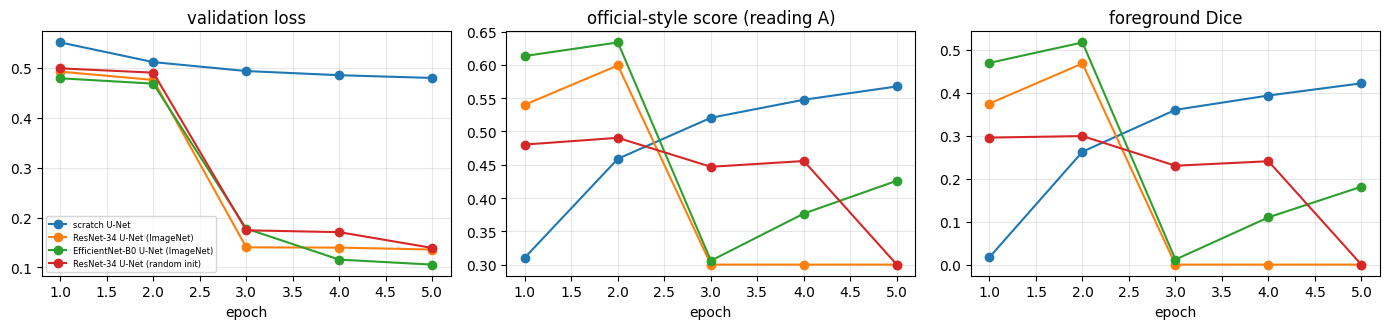

In [17]:
if RUN_TRAINING:
    all_rows = pd.concat([r["history"] for r in results.values()], ignore_index=True)
    all_rows.to_csv("/kaggle/working/m3_q8_q9_epochs.csv", index=False)
    print(all_rows.round(4).to_string(index=False))

    summary = pd.DataFrame([dict(model=l, parameters=r["params"], peak_gpu_gb=round(r["peak_gb"], 2), epoch1_fg=r["history"].iloc[0]["fg"],
                                 epoch5_val_loss=r["history"].iloc[-1]["val_loss"], epoch5_score_A=r["history"].iloc[-1]["A"], epoch5_score_B=r["history"].iloc[-1]["B"],
                                 epoch5_gap=r["history"].iloc[-1]["gap"], mean_epoch_s=r["history"]["time_s"].mean()) for l, r in results.items()]).set_index("model")
    print(); print(summary.round(4).to_string())

    fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
    for l, r in results.items():
        h = r["history"]
        axes[0].plot(h["epoch"], h["val_loss"], marker="o", label=l); axes[1].plot(h["epoch"], h["A"], marker="o", label=l); axes[2].plot(h["epoch"], h["fg"], marker="o", label=l)
    for a, t in zip(axes, ["validation loss", "official-style score (reading A)", "foreground Dice"]):
        a.set_title(t); a.set_xlabel("epoch"); a.grid(alpha=0.3)
    axes[0].legend(fontsize=6); plt.tight_layout(); plt.savefig("/kaggle/working/m3_q8_q9_curves.png", dpi=120); plt.show()

## D6. Answers in the form's format
The code prints the evidence and the answer lines. Rules used (stated so you can defend them):
- **Q8.1** winner = the model with the lower validation loss **and** the higher score at epoch 5 (reading A); if the two criteria disagree the line says so.
- **Q8.3** gap = validation loss minus training loss at epoch 5; "tighter" = smaller absolute gap.
- **Q8.4** score improvement = pretrained ResNet-34 score minus scratch score at epoch 5. The question's ranges leave 0.08 to 0.10 uncovered; the line says so if the value falls there.
- **Q9.3** "competitive" = EfficientNet-B0 score within 0.02 of ResNet-34 or higher, at epoch 5.

In [18]:
if RUN_TRAINING:
    S, R, E = results["scratch U-Net"], results["ResNet-34 U-Net (ImageNet)"], results["EfficientNet-B0 U-Net (ImageNet)"]
    last = lambda r, c: float(r["history"].iloc[-1][c])
    first = lambda r, c: float(r["history"].iloc[0][c])

    lower_loss = "pretrained" if last(R, "val_loss") < last(S, "val_loss") else "scratch"
    higher_score = "pretrained" if last(R, "A") > last(S, "A") else "scratch"
    winner = lower_loss if lower_loss == higher_score else f"mixed (lower loss: {lower_loss}, higher score: {higher_score})"
    faster = "pretrained" if first(R, "fg") > first(S, "fg") else "scratch"
    tighter = "Yes" if abs(last(R, "gap")) < abs(last(S, "gap")) else "No"
    delta = last(R, "A") - last(S, "A")
    if delta < 0.02: rng = "< +0.02"
    elif delta <= 0.08: rng = "+0.02 to +0.08"
    elif delta > 0.10: rng = "> +0.10"
    else: rng = "between +0.08 and +0.10 (not covered by the options; choose the nearest and explain)"
    print(f"epoch 5 val loss: scratch {last(S, 'val_loss'):.4f} | ResNet-34 {last(R, 'val_loss'):.4f}")
    print(f"epoch 5 score A: scratch {last(S, 'A'):.4f} | ResNet-34 {last(R, 'A'):.4f} | improvement {delta:+.4f}")
    print(f"epoch 1 foreground Dice: scratch {first(S, 'fg'):.4f} | ResNet-34 {first(R, 'fg'):.4f}")
    print(f"epoch 5 gap (val - train): scratch {last(S, 'gap'):+.4f} | ResNet-34 {last(R, 'gap'):+.4f}")
    print(f"Q8 winning_model; faster_epoch1_model; tighter_gap_yes_no; score_improvement_range: {winner}; {faster}; {tighter}; {rng}")

    ratio_runs = round(R["params"] / E["params"])
    edge = "resnet34" if R["peak_gb"] < E["peak_gb"] else "efficientnet-b0"
    competitive = "Yes" if last(E, "A") >= last(R, "A") - 0.02 else "No"
    print(f"\nparameters: ResNet-34 {R['params']:,} | EfficientNet-B0 {E['params']:,} | peak GPU memory: ResNet-34 {R['peak_gb']:.2f} GB | EfficientNet-B0 {E['peak_gb']:.2f} GB")
    print(f"epoch 5 score A: ResNet-34 {last(R, 'A'):.4f} | EfficientNet-B0 {last(E, 'A'):.4f}")
    print(f"Q9 param_ratio; edge_backbone; competitive_yes_no; convolution_technique: {ratio_runs}; {edge}; {competitive}; (write the technique from Part 3)")
    ANSWERS["Q8"] = dict(winning_model=winner, faster_epoch1_model=faster, tighter_gap_yes_no=tighter, score_improvement_range=rng)
    ANSWERS["Q9_training"] = dict(param_ratio=ratio_runs, edge_backbone=edge, competitive_yes_no=competitive, convolution_technique="(write the technique from Part C)")

epoch 5 val loss: scratch 0.4796 | ResNet-34 0.1359
epoch 5 score A: scratch 0.5676 | ResNet-34 0.3000 | improvement -0.2676
epoch 1 foreground Dice: scratch 0.0172 | ResNet-34 0.3749
epoch 5 gap (val - train): scratch -0.0047 | ResNet-34 -0.0010
Q8 winning_model; faster_epoch1_model; tighter_gap_yes_no; score_improvement_range: mixed (lower loss: pretrained, higher score: scratch); pretrained; Yes; < +0.02

parameters: ResNet-34 24,430,532 | EfficientNet-B0 6,251,328 | peak GPU memory: ResNet-34 2.10 GB | EfficientNet-B0 2.50 GB
epoch 5 score A: ResNet-34 0.3000 | EfficientNet-B0 0.4260
Q9 param_ratio; edge_backbone; competitive_yes_no; convolution_technique: 4; resnet34; Yes; (write the technique from Part 3)


## D7. Notes for the report
- The control run (random ResNet-34) separates **pretraining** from **architecture**: compare it with both the scratch U-Net and the pretrained ResNet-34.
- Peak memory depends on the activations (feature maps kept for backpropagation), not only on the parameter count; look at the measured numbers before answering Q9.2.
- All runs are in W&B under the names listed at the top, with the same configuration, which also gives you the "three runs compared on common metrics" required by the course.

# Summary of answer lines
All answers in the form's format, collected from the cells above. Part D entries appear only if `RUN_TRAINING` was `True`. The written explanations (the *my answer* cells) are yours to fill in.

In [19]:
import json
print(json.dumps(ANSWERS, indent=2, default=str))

{
  "Q1": {
    "H_bottle": 8,
    "W_bottle": 50,
    "mismatch_px": 1,
    "downsample_factor": 256.0
  },
  "Q3": {
    "sum_or_mean": "sum",
    "memory_factor": 3.0
  },
  "Q4": {
    "k_eff_r6": 13,
    "k_eff_r12": 25
  },
  "Q5": {
    "loss_model1": 0.9851,
    "loss_model2": 0.0524
  },
  "Q6": "Yes",
  "Q2": {
    "more_efficient_model": "efficientnet-b0",
    "param_diff": 18179204,
    "trainable_pct": 12.9
  },
  "Q9_param_ratio": 4,
  "Q8": {
    "winning_model": "mixed (lower loss: pretrained, higher score: scratch)",
    "faster_epoch1_model": "pretrained",
    "tighter_gap_yes_no": "Yes",
    "score_improvement_range": "< +0.02"
  },
  "Q9_training": {
    "param_ratio": 4,
    "edge_backbone": "resnet34",
    "competitive_yes_no": "Yes",
    "convolution_technique": "(write the technique from Part C)"
  }
}
